# Stage 3：余剰あり（s > 0）の正解で分離状態を作り、推定を含めた全工程で協力を検出できるか

設計書: `docs/stage3_design_2026-11-11.md`

- **正解の名目速度関数**：OV スケール形 V_ij(h) = V_ii(a_ij·h)、a2, b1 = 論文 Table 5（2A-1 §8、2A-3 §5 と同じ。形・最高速度・車長は仮置き）
- **評価するスナップショット（D_eval）**：K 車線のうちトラック専用が k 車線の完全分離（p2 = k/K）
  - E-L3：分離かつ NE（協力の正解）。(ρ, λ_true) を決めて、そうなる P2 を逆算する
  - E-L4：分離だが NE でない（帯の外の P2、および P2 = k/K の完全分離）
  - E-mix：同じ (ρ, P2) のランダム混合（s > 0 なので L2）
- **推定用データ（D_fit）**：正解の h_ij(v) からペア記録を直接作り、ノイズを加える。分離状態には C-T / T-C のペアがないので、a2, b1 は D_fit から推定する
- **段階（一度に一つだけ変える）**

| 段階 | アルゴリズムの関数 | D_fit | 評価点の観測 |
|---|---|---|---|
| 3-0 | 真の OV 関数（oracle） | 不要 | ノイズなし |
| 3-1 | 論文形をフィット | ノイズなし・各2000件・速度 2〜85 km/h | ノイズなし |
| 3-2 | 論文形をフィット | ＋ノイズ・NGSIM 並みの件数 | ノイズなし |
| 3-3 | 論文形をフィット | ＋速度範囲を 15〜60 km/h に制限 | ノイズなし |
| 3-4 | 3-3 と同じフィット | 3-3 と同じ | ＋観測ノイズ |

正解ラベルは Stage 1 と同じく道路シェアで決める（Eq.11 は使わない）。アルゴリズムの判定は src（whole_pipeline）の関数をそのまま使う。

In [1]:
import sys, os, io, time, contextlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nlopt
from scipy.optimize import brentq, minimize_scalar

%load_ext autoreload
%autoreload 2

ROOT = Path(os.path.abspath("../.."))   # notebooks/check → notebooks → ルート
sys.path.append(str(ROOT))

from src.ring_equilibrium import (make_ov_nominal, true_1pipe_speed, separated_speeds, surplus_at,
                                  separation_speed, at_speed_cap, h_eq, R_eq, u_nominal, v_range,
                                  CAR, TRUCK)
from src.whole_pipeline import (fit_nominal_speed_logistic, fit_nominal_speed_underwood,
                                fit_scaling_parameter_logistic, fit_scaling_parameter_underwood,
                                solve_1pipe_speed, compute_min_road_share, compute_cooperation_surplus,
                                classify_traffic_regime, fit_surplus_split)

warnings.filterwarnings('ignore', category=RuntimeWarning)

OUT = ROOT / "results" / "stage3_2026-11-12"
OUT.mkdir(parents=True, exist_ok=True)


def quiet(func, *args, **kwargs):
    #src の関数は途中経過を print するので、何十回も回す実験では表示を止める
    with contextlib.redirect_stdout(io.StringIO()):
        return func(*args, **kwargs)

## 0. パラメータと実験条件

設計書 §7 の「決めてほしいこと」は、ひとまず次の値で進める（このセルを変えれば全体が変わる）
- (a) OV の形：仮置きのまま（2A-1 / 2A-3 と同じ）
- (b) set T の対照：入れない
- (c) ノイズ：論文のフィット MAE に近くなる値（σ_h = 0.10、σ_v = 2 km/h → C-C 約7.6、C-T 約7.2 km/h。論文は 6.7 / 7.4 km/h）
- (d) λ：λ_true ごとに回収できるかを主に見る。Chen 流の「協力ありと判定された全スナップショットで1つの λ̂」は補足
- (e) K = 3（p2 = 1/3）と K = 4（p2 = 1/4）の両方

In [2]:
# 正解の名目速度関数：OV スケール形 + 論文 Table 5 の a2, b1
A2_TRUE, B1_TRUE = 0.4528, 2.5996
TRUTH = make_ov_nominal(form='scale', scale={(1, 2): A2_TRUE, (2, 1): B1_TRUE})

# 評価用スナップショット（D_eval）
RHO_LIST = [30, 40, 50, 60]          # 各車線の全体の密度 (veh/km/lane)
LAM_LIST = [0.1, 0.3, 0.5, 0.7, 0.9] # λ_true（乗用車の取り分。p1 = p1* + λ·s）
LAYOUTS = [(3, 1), (4, 1)]           # (車線数 K, トラック車線数 k) → p2 = k/K
L4_OFFSET = 0.03                     # L4 の対照：L3 の帯の端から P2 をこれだけ外す
EPS_LIST = [1e-6, 0.5, 1.0, 2.0]     # ε (km/h)。1e-6 は ε=0 の代わり

# 推定用データ（D_fit）
MODE_PAIR = {1: (CAR, CAR), 2: (CAR, TRUCK), 3: (TRUCK, CAR), 4: (TRUCK, TRUCK)}  # mode_id → (自車, 先行車)
N_AMPLE = {1: 2000, 2: 2000, 3: 2000, 4: 2000}           # 3-1：十分な件数
NGSIM_PAIRS = {1: 1451, 2: 65, 3: 48, 4: 6}              # NGSIM df_final のペア数
REC_PER_PAIR = 5                                         # 1ペアから独立に近い記録が何件取れるか（仮置き）
N_NGSIM = {m: n * REC_PER_PAIR for m, n in NGSIM_PAIRS.items()}
V_FULL = (2.0, 85.0)                 # 3-1, 3-2：速度の範囲 (km/h)。トラックの最高速度 90 の手前まで
V_NGSIM = (15.0, 60.0)               # 3-3, 3-4：NGSIM の渋滞時に近い範囲（仮置き）
SIGMA_H = 0.10                       # 車間のばらつき：h × exp(N(0, σ_h))
SIGMA_V = 2.0                        # 速度の計測誤差 (km/h)

# 観測ノイズ（3-4）：クラス平均速度の誤差 = σ_ind / √(その区間の台数)
SIGMA_U_IND = 5.0                    # 1台ごとの速度のばらつき (km/h)。仮置き（NGSIM の u1_sd, u2_sd で確認できる）
L_OBS_KM = 0.5                       # 観測区間の長さ（NGSIM I-80 は約 0.5 km）
N_OBS_DRAW = 2                       # 1回のフィットにつき何回ノイズを引くか

R_31 = 5                             # 3-1 の反復回数（乱数とISRESの初期値だけが変わる）
R_MAIN = 50                          # 3-2, 3-3, 3-4 の反復回数
SEED = 20261112

STAGES = ['3-0', '3-1', '3-2', '3-3', '3-4']
STAGE_COLORS = dict(zip(STAGES, plt.get_cmap('tab10').colors[:5]))   # 段階の色は固定
RHO_COLORS = dict(zip(RHO_LIST, ['#1f77b4', '#2ca02c', '#ff7f0e', '#d62728']))

## 1. 正解の状態（D_eval）

- 正解の基準 = ランダム混合の1-pipe速度 v_true（`true_1pipe_speed`）と、そこでの p1*, p2*, s（`surplus_at`）
- 分離状態の速度：トラックは道路の p2 = k/K、乗用車は 1 − p2 を使う → ũ1 = V11(ρ1/p1)、ũ2 = V22(ρ2/p2)（`separated_speeds`）
- ラベル：s > 0 かつ p1 ≥ p1*, p2 ≥ p2* なら L3（このとき λ_true = (p1 − p1*)/s）、そうでなければ L4
- 混合状態：ũ1 = ũ2 = v_true。s > 0 なら L2
- L3 になる P2 の帯は狭い（幅 ≈ s）ので、**(ρ, λ_true) から P2 を逆算する**。帯の中で λ は P2 について単調に増える（トラックが増えるほど乗用車の車線が空く）

In [3]:
def reference_light(rho1, rho2):
    #v_true と p1*, p2*, s だけ（P2 の逆算で何百回も呼ぶので u_sep は計算しない）
    v = true_1pipe_speed(TRUTH, rho1, rho2)
    sv = surplus_at(TRUTH, rho1, rho2, v)
    return v, float(sv['p1_star']), float(sv['p2_star']), float(sv['s'])


def truth_reference(rho1, rho2):
    #正解の基準一式（u_sep と、速度上限に張り付いていないかも含む）
    v, p1s, p2s, s = reference_light(rho1, rho2)
    return {'v_true': v, 'p1s_true': p1s, 'p2s_true': p2s, 's_true': s,
            'u_sep_true': separation_speed(TRUTH, rho1, rho2),
            'cap': bool(at_speed_cap(TRUTH, rho1, rho2, v))}


def truth_separated(rho, P2, K, k):
    #K車線のうちk車線がトラック専用の完全分離
    rho1, rho2 = rho * (1 - P2), rho * P2
    p2 = k / K
    p1 = 1 - p2
    ref = truth_reference(rho1, rho2)
    u1, u2 = separated_speeds(TRUTH, rho1, rho2, p2)
    is_ne = (ref['s_true'] > 0) and (p1 >= ref['p1s_true']) and (p2 >= ref['p2s_true'])
    lam = (p1 - ref['p1s_true']) / ref['s_true'] if is_ne else np.nan
    return {'rho1': rho1, 'rho2': rho2, 'p1': p1, 'p2': p2, 'u1_obs': u1, 'u2_obs': u2,
            'label': 'L3' if is_ne else 'L4', 'lam_true': lam, **ref}


def truth_mixed(rho, P2):
    #全車線ランダム混合（平均の m̄）。両クラスとも v_true で走る
    rho1, rho2 = rho * (1 - P2), rho * P2
    ref = truth_reference(rho1, rho2)
    return {'rho1': rho1, 'rho2': rho2, 'p1': np.nan, 'p2': np.nan,
            'u1_obs': ref['v_true'], 'u2_obs': ref['v_true'],
            'label': 'L2' if ref['s_true'] > 0 else 'L1', 'lam_true': np.nan, **ref}


def lam_of_P2(rho, P2, K, k):
    #分離状態の λ = (p1 − p1*)/s を P2 の関数として返す（帯の外でもそのまま計算。s<=0 は NaN）
    v, p1s, p2s, s = reference_light(rho * (1 - P2), rho * P2)
    return (1 - k / K - p1s) / s if s > 0 else np.nan


def P2_for_lambda(rho, lam, K, k, grid):
    #λ_true になる P2 を探す。grid = (P2の格子, そこでのλ) で符号が変わる区間を見つけて brentq
    P2_grid, lam_grid = grid
    for a, b, la, lb in zip(P2_grid[:-1], P2_grid[1:], lam_grid[:-1], lam_grid[1:]):
        if np.isfinite(la) and np.isfinite(lb) and (la - lam) * (lb - lam) <= 0:
            return brentq(lambda P: lam_of_P2(rho, P, K, k) - lam, a, b, xtol=1e-12)
    return np.nan

In [4]:
t0 = time.time()
rows = []
for K, k in LAYOUTS:
    for rho in RHO_LIST:
        P2_grid = np.linspace(0.02, 0.6, 291)
        grid = (P2_grid, np.array([lam_of_P2(rho, P, K, k) for P in P2_grid]))
        P2_edge0 = P2_for_lambda(rho, 0.0, K, k, grid)   # 帯の下端（λ=0）
        P2_edge1 = P2_for_lambda(rho, 1.0, K, k, grid)   # 帯の上端（λ=1）
        base = {'K': K, 'k': k, 'rho': rho}

        for lam in LAM_LIST:
            P2 = P2_for_lambda(rho, lam, K, k, grid)
            rows.append({'group': 'E-L3', **base, 'P2': P2, 'lam_target': lam, **truth_separated(rho, P2, K, k)})
            rows.append({'group': 'E-mix', **base, 'P2': P2, 'lam_target': lam, **truth_mixed(rho, P2)})

        for name, P2 in [('below', P2_edge0 - L4_OFFSET), ('above', P2_edge1 + L4_OFFSET), ('equal', k / K)]:
            rows.append({'group': 'E-L4', **base, 'P2': P2, 'lam_target': np.nan, 'l4_case': name,
                         **truth_separated(rho, P2, K, k)})

D_EVAL = pd.DataFrame(rows)
D_EVAL['du1_true'] = D_EVAL['u1_obs'] - D_EVAL['v_true']   # 分離時の速度 − v_true
D_EVAL['du2_true'] = D_EVAL['u2_obs'] - D_EVAL['v_true']
D_EVAL['snap_id'] = np.arange(len(D_EVAL))
print(f"D_eval: {len(D_EVAL)} スナップショット（{time.time() - t0:.1f} s）")
print(D_EVAL.groupby(['group', 'label']).size())

#自己チェック
l3 = D_EVAL[D_EVAL['group'] == 'E-L3']
print("E-L3 がすべて L3:", (l3['label'] == 'L3').all(),
      "/ max|λ_true − λ_target| =", f"{(l3['lam_true'] - l3['lam_target']).abs().max():.1e}")
print("E-L4 がすべて L4:", (D_EVAL.loc[D_EVAL['group'] == 'E-L4', 'label'] == 'L4').all())
print("E-mix がすべて L2:", (D_EVAL.loc[D_EVAL['group'] == 'E-mix', 'label'] == 'L2').all())
print("速度上限に張り付いた点:", int(D_EVAL['cap'].sum()))
D_EVAL.to_csv(OUT / "stage3_d_eval.csv", index=False)

D_eval: 104 スナップショット（1.9 s）
group  label
E-L3   L3       40
E-L4   L4       24
E-mix  L2       40
dtype: int64
E-L3 がすべて L3: True / max|λ_true − λ_target| = 1.3e-11
E-L4 がすべて L4: True
E-mix がすべて L2: True
速度上限に張り付いた点: 0


In [5]:
#E-L3 の中身：s_true と、分離時に各クラスが v_true よりどれだけ速いか（du1, du2）
show = l3.pivot_table(index=['K', 'rho'], columns='lam_target',
                      values=['P2', 's_true', 'du1_true', 'du2_true'])
show.round(3)

P2                             du1_true                       \
lam_target    0.1    0.3    0.5    0.7    0.9      0.1    0.3    0.5    0.7   
K rho                                                                         
3 30        0.236  0.245  0.255  0.266  0.277    1.162  3.613  6.238  9.044   
  40        0.232  0.240  0.248  0.257  0.266    0.529  1.641  2.827  4.095   
  50        0.226  0.232  0.239  0.245  0.252    0.210  0.644  1.099  1.576   
  60        0.220  0.225  0.229  0.234  0.239    0.089  0.272  0.460  0.654   
4 30        0.168  0.175  0.183  0.191  0.199    0.856  2.665  4.613  6.710   
  40        0.166  0.172  0.179  0.186  0.193    0.432  1.342  2.317  3.361   
  50        0.162  0.167  0.172  0.177  0.183    0.178  0.547  0.936  1.346   
  60        0.158  0.162  0.166  0.170  0.174    0.078  0.238  0.404  0.576   

                   du2_true                               s_true         \
lam_target     0.9      0.1     0.3     0.5    0.7    0.9    0.1    0.3   
K rho                                                                     
3 30        12.035   19.266  15.871  11.872  7.364  2.502  0.055  0.056   
  40         5.448   15.857  11.800   8.010  4.541  1.424  0.048  0.049   
  50         2.076    6.993   5.123   3.443  1.942  0.608  0.039  0.039   
  60         0.853    2.971   2.200   1.496  0.855  0.271  0.029  0.029   
4 30         8.965   18.385  15.533  11.949  7.635  2.673  0.044  0.045   
  40         4.480   19.039  14.379   9.886  5.664  1.790  0.040  0.041   
  50         1.777    9.054   6.658   4.486  2.535  0.794  0.033  0.033   
  60         0.755    3.985   2.950   2.005  1.145  0.363  0.025  0.026   

                                 
lam_target    0.5    0.7    0.9  
K rho                            
3 30        0.057  0.058  0.060  
  40        0.050  0.051  0.051  
  50        0.040  0.040  0.040  
  60        0.029  0.030  0.030  
4 30        0.046  0.048  0.049  
  40        0.042  0.043  0.044  
  50        0.034  0.034  0.035  
  60        0.026  0.026  0.026

## 2. Stage 3-0：真の関数を使ったときの検出（oracle）

- アルゴリズム側も真の OV 関数を使う：Eq.5 の一般形 Σ_i Σ_j (ρ_i ρ_j / ρ) / R_ij(u) = 1 をスケーリング仮定なしに解く
  （ランダム混合のリングと同じ式なので v_true と一致するはず → 自己チェック）
- p*, s は `surplus_at`、判定は src の `classify_traffic_regime`（ε ごと）
- λ̂ は論文 Eq.12 の損失を OV の自クラス関数で最小化（src の `predict_speed_with_lambda` はロジスティック / Underwood 固定のため、ここだけ自作）
- ここで見逃すものは**推定の問題ではなく、ε と du の大きさで決まる検出限界**

In [6]:
def eq5_speed_general(nominal, rho1, rho2):
    #一般形 Eq.5：Σ_i Σ_j (ρ_i ρ_j / ρ_tot) / R_ij(u) = 1 を解く（4つの関数をそのまま使う）
    rho = rho1 + rho2
    dens = {(1, 1): rho1 * rho1 / rho, (1, 2): rho1 * rho2 / rho,
            (2, 1): rho2 * rho1 / rho, (2, 2): rho2 * rho2 / rho}
    used = [p for p, d in dens.items() if d > 0]
    lo = max(v_range(nominal, *p)[0] for p in used)
    hi = min(v_range(nominal, *p)[1] for p in used)
    f = lambda u: sum(dens[p] / float(R_eq(nominal, *p, u)) for p in used) - 1.0
    if f(lo) > 0 or f(hi) < 0:
        return np.nan
    return brentq(f, lo, hi, xtol=1e-12)


def lambda_loss_general(lam, df, u1_fn, u2_fn, w1=0.5, w2=0.5):
    #論文 Eq.12：L(λ) = mean_t [ w1|ũ1 − û1| + w2|ũ2 − û2| ]^2。û_i = u_i(ρ_i / p_i)
    p1 = df['p1_star'] + lam * df['s']
    p2 = df['p2_star'] + (1 - lam) * df['s']
    if (p1 <= 0).any() or (p2 <= 0).any():
        return np.inf
    err = w1 * np.abs(df['u1_obs'] - u1_fn(df['rho1'] / p1)) + w2 * np.abs(df['u2_obs'] - u2_fn(df['rho2'] / p2))
    return float(np.mean(err ** 2))


def fit_lambda_general(df, u1_fn, u2_fn):
    res = minimize_scalar(lambda_loss_general, bounds=(0.0, 1.0), method='bounded', args=(df, u1_fn, u2_fn))
    return res.x


def judge(df, eps_list):
    #u_1pipe, s 列を持つ表に Eq.11 の判定と協力の有無を付ける（ε ごとに縦に積む）
    out = []
    for eps in eps_list:
        d = quiet(classify_traffic_regime, df, eps)
        d['eps'] = eps
        d['coop'] = (d['regime'] == '2-pipe') & (d['s'] > 0)
        out.append(d)
    return pd.concat(out, ignore_index=True)


def pooled_lambda(res, fitter):
    #Chen 流：協力ありと判定されたスナップショット全部（正解ラベルは使わない）で λ̂ を1つ推定
    rows = []
    for eps, d in res.groupby('eps'):
        dc = d[d['coop']]
        rows.append({'eps': eps, 'n_coop': len(dc), 'n_coop_L3': int((dc['label'] == 'L3').sum()),
                     'lam_pool': fitter(dc) if len(dc) > 0 else np.nan})
    return pd.DataFrame(rows)


TRUE_U1 = lambda rho: u_nominal(TRUTH, CAR, CAR, rho)
TRUE_U2 = lambda rho: u_nominal(TRUTH, TRUCK, TRUCK, rho)


def run_oracle(df_eval):
    df = df_eval.copy()
    df['u_1pipe'] = [eq5_speed_general(TRUTH, r1, r2) for r1, r2 in zip(df['rho1'], df['rho2'])]
    sv = [surplus_at(TRUTH, r1, r2, u) for r1, r2, u in zip(df['rho1'], df['rho2'], df['u_1pipe'])]
    df['p1_star'] = [float(x['p1_star']) for x in sv]
    df['p2_star'] = [float(x['p2_star']) for x in sv]
    df['s'] = [float(x['s']) for x in sv]
    df['lam_hat'] = [fit_lambda_general(df.loc[[i]], TRUE_U1, TRUE_U2) if df.at[i, 's'] > 0 else np.nan
                     for i in df.index]
    res = judge(df, EPS_LIST)
    pool = pooled_lambda(res, lambda d: fit_lambda_general(d, TRUE_U1, TRUE_U2))
    return res, pool


RES_30, POOL_30 = run_oracle(D_EVAL)
RES_30['stage'], RES_30['rep'] = '3-0', 0
POOL_30['stage'], POOL_30['rep'] = '3-0', 0

one = RES_30[RES_30['eps'] == EPS_LIST[0]]
print("自己チェック max|u*(Eq.5一般形) − v_true| =", f"{(one['u_1pipe'] - one['v_true']).abs().max():.1e} km/h")
print("自己チェック max|s − s_true| =", f"{(one['s'] - one['s_true']).abs().max():.1e}")
l3o = one[one['label'] == 'L3']
print("自己チェック max|λ̂ − λ_true|（L3, 1スナップショットずつ）=", f"{(l3o['lam_hat'] - l3o['lam_true']).abs().max():.1e}")

自己チェック max|u*(Eq.5一般形) − v_true| = 5.1e-13 km/h
自己チェック max|s − s_true| = 1.1e-14
自己チェック max|λ̂ − λ_true|（L3, 1スナップショットずつ）= 2.2e-06


## 3. 推定用データ（D_fit）と論文形のフィット

- 記録 1件 = (mode_id, 微視的密度 1000/h, 速度 v_Vel [ft/s])。src のフィット関数にそのまま入る形
- 作り方：速度 v を範囲内で一様に抽出 → 正解の車間 h = h_ij(v) → 車間に exp(N(0, σ_h))、速度に N(0, σ_v) を加える
- フィット：src の `fit_nominal_speed_logistic`（C-C）、`fit_nominal_speed_underwood`（T-T）、`fit_scaling_parameter_*`（a2 ← C-T、b1 ← T-C）。ISRES の乱数は `nlopt.srand` で固定
- 速度は v_lo〜v_hi で一様に抽出（NGSIM の実際の分布とは違う。範囲の効果だけを見るため）

In [7]:
def make_fit_records(n_per_mode, v_lims, sigma_h, sigma_v, rng):
    frames = []
    for mode, (i, j) in MODE_PAIR.items():
        n = n_per_mode[mode]
        v_hi = min(v_lims[1], 0.97 * TRUTH['vmax'][i])
        v = rng.uniform(v_lims[0], v_hi, n)
        h = h_eq(TRUTH, i, j, v) * np.exp(rng.normal(0.0, sigma_h, n))
        v_obs = np.maximum(v + rng.normal(0.0, sigma_v, n), 0.1)
        frames.append(pd.DataFrame({'mode_id': mode, 'mdensity_veh_km': 1000.0 / h,
                                    'v_Vel': v_obs / 3.6 / 0.3048}))   # km/h → ft/s（src は ft/s を受け取る）
    return pd.concat(frames, ignore_index=True)


def fit_paper_form(df_fit, seed):
    nlopt.srand(int(seed))
    car = quiet(fit_nominal_speed_logistic, df_fit, 1)
    truck = quiet(fit_nominal_speed_underwood, df_fit, 4)
    a2 = quiet(fit_scaling_parameter_logistic, df_fit, 2, car)
    b1 = quiet(fit_scaling_parameter_underwood, df_fit, 3, truck)
    return {'car': car, 'truck': truck, 'a2': a2['scaling_param'], 'b1': b1['scaling_param'],
            'mae': {'CC': car['test_mae'], 'TT': truck['test_mae'], 'CT': a2['test_mae'], 'TC': b1['test_mae']}}


def fit_row(fit):
    #保存用に1行へ平たくする
    row = {f"car_{k}": fit['car'][k] for k in ('ub', 'uf', 'rhoc', 'theta1', 'theta2')}
    row.update({f"truck_{k}": fit['truck'][k] for k in ('uf', 'rhoc')})
    row.update({'a2': fit['a2'], 'b1': fit['b1']})
    row.update({f"mae_{k}": v for k, v in fit['mae'].items()})
    return row


#例：1回分のフィット（各段階の設定）
for name, n, vl, sh, sv in [('3-1', N_AMPLE, V_FULL, 0.0, 0.0), ('3-2', N_NGSIM, V_FULL, SIGMA_H, SIGMA_V),
                            ('3-3', N_NGSIM, V_NGSIM, SIGMA_H, SIGMA_V)]:
    f = fit_paper_form(make_fit_records(n, vl, sh, sv, np.random.default_rng(SEED)), SEED)
    print(name, {k: round(v, 3) for k, v in fit_row(f).items()})
print("論文の MAE (km/h): CC 6.7, TT 4.0, CT 7.4, TC 10.4")

3-1 {'car_ub': np.float64(11.569), 'car_uf': np.float64(129.192), 'car_rhoc': np.float64(79.875), 'car_theta1': np.float64(11.934), 'car_theta2': np.float64(42.356), 'truck_uf': np.float64(150.0), 'truck_rhoc': np.float64(22.178), 'a2': np.float64(0.454), 'b1': np.float64(2.656), 'mae_CC': 2.553, 'mae_TT': 10.465, 'mae_CT': 2.487, 'mae_TC': 10.566}


3-2 {'car_ub': np.float64(7.312), 'car_uf': np.float64(114.388), 'car_rhoc': np.float64(91.471), 'car_theta1': np.float64(13.488), 'car_theta2': np.float64(50.544), 'truck_uf': np.float64(150.0), 'truck_rhoc': np.float64(19.256), 'a2': np.float64(0.456), 'b1': np.float64(2.833), 'mae_CC': 7.513, 'mae_TT': 8.6, 'mae_CT': 8.628, 'mae_TC': 13.459}


3-3 {'car_ub': np.float64(14.284), 'car_uf': np.float64(95.5), 'car_rhoc': np.float64(102.304), 'car_theta1': np.float64(16.021), 'car_theta2': np.float64(59.296), 'truck_uf': np.float64(150.0), 'truck_rhoc': np.float64(19.372), 'a2': np.float64(0.454), 'b1': np.float64(2.692), 'mae_CC': 6.325, 'mae_TT': 5.081, 'mae_CT': 7.146, 'mae_TC': 8.535}
論文の MAE (km/h): CC 6.7, TT 4.0, CT 7.4, TC 10.4


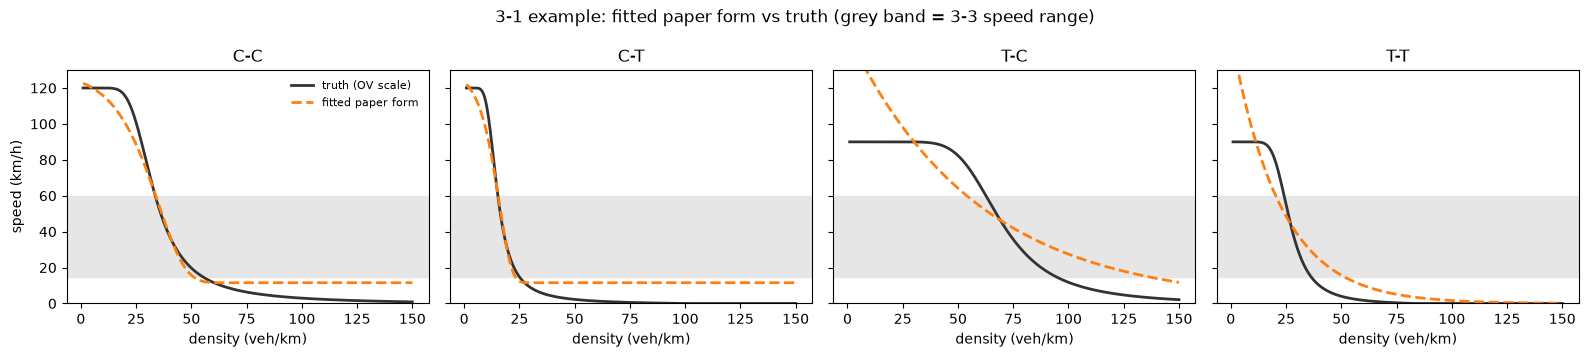

In [8]:
#3-1 の設定（ノイズなし）で、フィットした論文形と正解の OV 曲線を重ねる
f_demo = fit_paper_form(make_fit_records(N_AMPLE, V_FULL, 0.0, 0.0, np.random.default_rng(SEED)), SEED)
from src.whole_pipeline import logistic_speed_density, underwood_speed_density
rho_ax = np.linspace(1, 150, 400)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, (mode, (i, j)) in zip(axes, MODE_PAIR.items()):
    ax.plot(rho_ax, u_nominal(TRUTH, i, j, rho_ax), color='0.2', lw=2, label='truth (OV scale)')
    c, t = f_demo['car'], f_demo['truck']
    if mode == 1:
        fit_curve = logistic_speed_density(rho_ax, c['ub'], c['uf'], c['rhoc'], c['theta1'], c['theta2'])
    elif mode == 2:
        fit_curve = logistic_speed_density(rho_ax / f_demo['a2'], c['ub'], c['uf'], c['rhoc'], c['theta1'], c['theta2'])
    elif mode == 3:
        fit_curve = underwood_speed_density(rho_ax / f_demo['b1'], t['uf'], t['rhoc'])
    else:
        fit_curve = underwood_speed_density(rho_ax, t['uf'], t['rhoc'])
    ax.plot(rho_ax, fit_curve, color=STAGE_COLORS['3-1'], lw=2, ls='--', label='fitted paper form')
    ax.axhspan(*V_NGSIM, color='0.9', zorder=0)
    ax.set_title(['C-C', 'C-T', 'T-C', 'T-T'][mode - 1])
    ax.set_xlabel('density (veh/km)')
    ax.set_ylim(0, 130)
axes[0].set_ylabel('speed (km/h)')
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('3-1 example: fitted paper form vs truth (grey band = 3-3 speed range)')
fig.tight_layout()
fig.savefig(OUT / "stage3_fit_example.png", dpi=150)
plt.show()

## 4. アルゴリズム（論文形）を D_eval に当てる

Step 3a〜6 は src の関数をそのまま使う：`solve_1pipe_speed`（印刷版）→ `compute_min_road_share` → `compute_cooperation_surplus` → `classify_traffic_regime` → 協力あり = 2-pipe かつ s > 0 → `fit_surplus_split`（λ̂）
- λ̂ は2通り：(i) スナップショット1つずつ（s̃ > 0 の行）、(ii) Chen 流に「協力ありと判定された行すべて」で1つ
- 観測ノイズ（3-4）：クラス平均速度に N(0, σ_ind / √n_i) を加える。n_i = ρ_i · K · L_obs（観測区間の台数）

In [9]:
def run_algorithm_paper(df_eval, fit):
    car, truck, a2, b1 = fit['car'], fit['truck'], fit['a2'], fit['b1']
    df = df_eval.copy()

    def solve(r1, r2):
        try:
            return solve_1pipe_speed(r1, r2, car, truck, a2, b1, 'printed')
        except ValueError:
            return np.nan

    df['u_1pipe'] = [solve(r1, r2) for r1, r2 in zip(df['rho1'], df['rho2'])]
    df = quiet(compute_min_road_share, df, car, truck)
    df = quiet(compute_cooperation_surplus, df)
    df['lam_hat'] = [quiet(fit_surplus_split, df.loc[[i]], car, truck) if df.at[i, 's'] > 0 else np.nan
                     for i in df.index]
    res = judge(df, EPS_LIST)
    pool = pooled_lambda(res, lambda d: quiet(fit_surplus_split, d, car, truck))
    return res, pool


def add_obs_noise(df_eval, rng):
    d = df_eval.copy()
    n1 = d['rho1'] * d['K'] * L_OBS_KM
    n2 = d['rho2'] * d['K'] * L_OBS_KM
    d['u1_obs'] = d['u1_obs'] + rng.normal(0.0, 1.0, len(d)) * SIGMA_U_IND / np.sqrt(n1)
    d['u2_obs'] = d['u2_obs'] + rng.normal(0.0, 1.0, len(d)) * SIGMA_U_IND / np.sqrt(n2)
    return d


def run_fitted_stage(stage, n_per_mode, v_lims, sigma_h, sigma_v, R, seed0):
    res_all, pool_all, fit_all, fit_dicts = [], [], [], []
    t0 = time.time()
    for r in range(R):
        rng = np.random.default_rng(seed0 + r)
        fit = fit_paper_form(make_fit_records(n_per_mode, v_lims, sigma_h, sigma_v, rng), seed0 + r)
        res, pool = run_algorithm_paper(D_EVAL, fit)
        for d in (res, pool):
            d['stage'], d['rep'] = stage, r
        res_all.append(res)
        pool_all.append(pool)
        fit_all.append({'stage': stage, 'rep': r, **fit_row(fit)})
        fit_dicts.append(fit)
    print(f"{stage}: {R} 回 ({time.time() - t0:.0f} s)")
    return pd.concat(res_all, ignore_index=True), pd.concat(pool_all, ignore_index=True), pd.DataFrame(fit_all), fit_dicts

## 5. Stage 3-1〜3-4 を実行

In [10]:
RES_31, POOL_31, FIT_31, _ = run_fitted_stage('3-1', N_AMPLE, V_FULL, 0.0, 0.0, R_31, SEED + 1000)
RES_32, POOL_32, FIT_32, _ = run_fitted_stage('3-2', N_NGSIM, V_FULL, SIGMA_H, SIGMA_V, R_MAIN, SEED + 2000)
RES_33, POOL_33, FIT_33, FITS_33 = run_fitted_stage('3-3', N_NGSIM, V_NGSIM, SIGMA_H, SIGMA_V, R_MAIN, SEED + 3000)

#3-4：3-3 のフィットをそのまま使い、評価点の観測速度にだけノイズを加える
res_34, pool_34 = [], []
t0 = time.time()
rng_obs = np.random.default_rng(SEED + 4000)
for r, fit in enumerate(FITS_33):
    for draw in range(N_OBS_DRAW):
        res, pool = run_algorithm_paper(add_obs_noise(D_EVAL, rng_obs), fit)
        for d in (res, pool):
            d['stage'], d['rep'], d['draw'] = '3-4', r, draw
        res_34.append(res)
        pool_34.append(pool)
RES_34, POOL_34 = pd.concat(res_34, ignore_index=True), pd.concat(pool_34, ignore_index=True)
print(f"3-4: {len(FITS_33)} フィット × {N_OBS_DRAW} 回 ({time.time() - t0:.0f} s)")

RES = pd.concat([RES_30, RES_31, RES_32, RES_33, RES_34], ignore_index=True)
POOL = pd.concat([POOL_30, POOL_31, POOL_32, POOL_33, POOL_34], ignore_index=True)
FITS = pd.concat([FIT_31, FIT_32, FIT_33], ignore_index=True)
FITS.to_csv(OUT / "stage3_fits.csv", index=False)
POOL.to_csv(OUT / "stage3_lambda_pooled.csv", index=False)
keep = ['stage', 'rep', 'draw', 'eps', 'snap_id', 'group', 'K', 'rho', 'P2', 'lam_target', 'label',
        'lam_true', 'v_true', 's_true', 'u_sep_true', 'u1_obs', 'u2_obs', 'u_1pipe', 'p1_star', 'p2_star',
        's', 'du1', 'du2', 'regime', 'coop', 'lam_hat']
RES[[c for c in keep if c in RES.columns]].to_csv(OUT / "stage3_results.csv", index=False)
print("保存:", OUT)

3-1: 5 回 (53 s)


3-2: 50 回 (508 s)


3-3: 50 回 (495 s)


3-4: 50 フィット × 2 回 (674 s)


保存: C:\Users\AMhetero\Documents\研究室\Game_Theory_Algorithm\results\stage3_2026-11-12


## 6. 推定されたパラメータ

正解（OV スケール形）の a2 = 0.4528、b1 = 2.5996。論文形は正解と形が違うので、ノイズなしでも一致する保証はない（a2, b1 以外は比べる正解がない）

In [11]:
FITS.groupby('stage')[['a2', 'b1', 'car_ub', 'car_uf', 'truck_uf', 'truck_rhoc',
                       'mae_CC', 'mae_CT', 'mae_TC', 'mae_TT']].describe(percentiles=[0.5]).T.round(3)

stage                 3-1      3-2      3-3
a2         count    5.000   50.000   50.000
           mean     0.453    0.452    0.454
           std      0.001    0.005    0.005
           min      0.452    0.442    0.443
           50%      0.453    0.452    0.454
           max      0.454    0.463    0.465
b1         count    5.000   50.000   50.000
           mean     2.598    2.581    2.623
           std      0.039    0.186    0.207
           min      2.544    2.132    1.650
           50%      2.614    2.603    2.630
           max      2.638    3.074    2.932
car_ub     count    5.000   50.000   50.000
           mean    11.845    7.581   15.841
           std      1.540    0.485    1.904
           min      9.283    6.162   11.898
           50%     12.337    7.524   16.108
           max     13.109    8.485   19.582
car_uf     count    5.000   50.000   50.000
           mean   128.903  128.169   87.427
           std      0.993    3.199   16.887
           min    127.207  109.540   55.420
           50%    129.121  129.243   86.407
           max    129.637  129.982  126.866
truck_uf   count    5.000   50.000   50.000
           mean   150.000  150.000  145.960
           std      0.000    0.000   14.505
           min    150.000  150.000   59.546
           50%    150.000  150.000  150.000
           max    150.000  150.000  150.000
truck_rhoc count    5.000   50.000   50.000
           mean    22.443   22.612   22.110
           std      0.143    1.566   11.318
           min     22.253   18.774   18.366
           50%     22.424   22.515   20.396
           max     22.652   27.240   99.999
mae_CC     count    5.000   50.000   50.000
           mean     2.454    7.528    6.373
           std      0.166    0.126    0.111
           min      2.213    7.299    6.074
           50%      2.449    7.515    6.383
           max      2.631    7.790    6.590
mae_CT     count    5.000   50.000   50.000
           mean     2.458    7.742    6.511
           std      0.076    0.648    0.438
           min      2.364    6.376    5.453
           50%      2.511    7.715    6.522
           max      2.515    9.164    7.638
mae_TC     count    5.000   50.000   50.000
           mean    10.482   11.413    7.524
           std      0.186    0.764    0.720
           min     10.345    9.982    5.934
           50%     10.415   11.308    7.397
           max     10.810   12.808    9.975
mae_TT     count    5.000   50.000   50.000
           mean    10.543   11.908    7.924
           std      0.301    2.445    1.688
           min     10.084    7.534    4.073
           50%     10.707   11.978    7.647
           max     10.780   17.532   12.400

## 7. 集計

スナップショットごとに2つの判定を分けて記録する
- **J1（s の符号）**：sign(s̃) = sign(s_true) か
- **J2（regime）**：Eq.11 の判定が正解の regime（L3 → 2-pipe、L4 → non-NE、L2 → 1-pipe）と一致するか
- **結果の分類**：協力あり（coop）/ 2-pipe だが s ≤ 0 / 1-pipe / non-NE / undefined（u* が解けない）
- Δu* = û* − v_true

In [12]:
TRUE_REGIME = {'L3': '2-pipe', 'L4': 'non-NE', 'L2': '1-pipe', 'L1': '1-pipe'}


def add_scores(res):
    d = res.copy()
    d['j1_ok'] = np.sign(d['s']) == np.sign(d['s_true'])
    d['j2_ok'] = d['regime'] == d['label'].map(TRUE_REGIME)
    d['du_star'] = d['u_1pipe'] - d['v_true']
    d['outcome'] = np.select(
        [d['regime'] == 'undefined', d['coop'], d['regime'] == '2-pipe', d['regime'] == '1-pipe'],
        ['undefined', 'coop', '2-pipe, s<=0', '1-pipe'], default='non-NE')
    return d


RES = add_scores(RES)
SUMMARY = (RES.groupby(['stage', 'eps', 'group'])
           .agg(n=('coop', 'size'), P_coop=('coop', 'mean'), J1_ok=('j1_ok', 'mean'), J2_ok=('j2_ok', 'mean'),
                du_star_median=('du_star', 'median'), du_star_absmax=('du_star', lambda x: x.abs().max()))
           .reset_index())
SUMMARY.to_csv(OUT / "stage3_summary.csv", index=False)

#検出率（E-L3）と偽協力率（E-L4, E-mix）：行 = 段階、列 = ε
table = SUMMARY.pivot_table(index='stage', columns=['group', 'eps'], values='P_coop')
table.round(3)

group     E-L3                                E-L4                             \
eps   0.000001 0.500000 1.000000 2.000000 0.000001 0.500000 1.000000 2.000000   
stage                                                                           
3-0      1.000    1.000    0.925    0.825    0.000    0.000    0.000    0.125   
3-1      0.730    0.770    0.785    0.735    0.017    0.033    0.042    0.100   
3-2      0.556    0.655    0.642    0.516    0.001    0.012    0.040    0.092   
3-3      0.289    0.300    0.313    0.346    0.102    0.103    0.104    0.107   
3-4      0.295    0.308    0.321    0.344    0.098    0.102    0.103    0.106   

group    E-mix                             
eps   0.000001 0.500000 1.000000 2.000000  
stage                                      
3-0      0.000    0.000    0.000    0.000  
3-1      0.595    0.355    0.180    0.045  
3-2      0.298    0.180    0.127    0.036  
3-3      0.275    0.274    0.272    0.270  
3-4      0.273    0.274    0.273    0.270

In [13]:
#E-L3 の結果の内訳（見逃しの理由）
OUTCOMES = ['coop', '1-pipe', 'non-NE', '2-pipe, s<=0', 'undefined']
brk = (RES[RES['group'] == 'E-L3'].groupby(['stage', 'eps'])['outcome']
       .value_counts(normalize=True).unstack(fill_value=0.0).reindex(columns=OUTCOMES, fill_value=0.0))
brk.round(3)

outcome          coop  1-pipe  non-NE  2-pipe, s<=0  undefined
stage eps                                                     
3-0   0.000001  1.000   0.000   0.000         0.000      0.000
      0.500000  1.000   0.000   0.000         0.000      0.000
      1.000000  0.925   0.075   0.000         0.000      0.000
      2.000000  0.825   0.175   0.000         0.000      0.000
3-1   0.000001  0.730   0.000   0.270         0.000      0.000
      0.500000  0.770   0.005   0.225         0.000      0.000
      1.000000  0.785   0.040   0.175         0.000      0.000
      2.000000  0.735   0.115   0.150         0.000      0.000
3-2   0.000001  0.556   0.000   0.440         0.004      0.000
      0.500000  0.655   0.039   0.302         0.004      0.000
      1.000000  0.642   0.116   0.238         0.004      0.000
      2.000000  0.516   0.286   0.194         0.004      0.000
3-3   0.000001  0.289   0.000   0.706         0.000      0.005
      0.500000  0.300   0.011   0.684         0.000      0.005
      1.000000  0.313   0.022   0.660         0.000      0.005
      2.000000  0.346   0.054   0.596         0.000      0.005
3-4   0.000001  0.295   0.000   0.700         0.000      0.005
      0.500000  0.308   0.006   0.681         0.000      0.005
      1.000000  0.321   0.017   0.657         0.000      0.005
      2.000000  0.344   0.057   0.594         0.000      0.005

In [14]:
#E-L4, E-mix の結果の内訳（何と判定されたか）
brk_fp = (RES[RES['group'] != 'E-L3'].groupby(['group', 'stage', 'eps'])['outcome']
          .value_counts(normalize=True).unstack(fill_value=0.0).reindex(columns=OUTCOMES, fill_value=0.0))
brk_fp.round(3)

outcome                coop  1-pipe  non-NE  2-pipe, s<=0  undefined
group stage eps                                                     
E-L4  3-0   0.000001  0.000   0.000   1.000         0.000      0.000
            0.500000  0.000   0.000   1.000         0.000      0.000
            1.000000  0.000   0.000   1.000         0.000      0.000
            2.000000  0.125   0.000   0.875         0.000      0.000
      3-1   0.000001  0.017   0.000   0.983         0.000      0.000
            0.500000  0.033   0.000   0.967         0.000      0.000
            1.000000  0.042   0.000   0.958         0.000      0.000
            2.000000  0.100   0.000   0.900         0.000      0.000
      3-2   0.000001  0.001   0.000   0.999         0.000      0.000
            0.500000  0.012   0.000   0.988         0.000      0.000
            1.000000  0.040   0.000   0.960         0.000      0.000
            2.000000  0.092   0.000   0.908         0.000      0.000
      3-3   0.000001  0.102   0.000   0.893         0.000      0.005
            0.500000  0.103   0.000   0.892         0.000      0.005
            1.000000  0.104   0.000   0.891         0.000      0.005
            2.000000  0.107   0.000   0.888         0.000      0.005
      3-4   0.000001  0.098   0.000   0.897         0.000      0.005
            0.500000  0.102   0.000   0.893         0.000      0.005
            1.000000  0.103   0.000   0.892         0.000      0.005
            2.000000  0.106   0.000   0.888         0.000      0.005
E-mix 3-0   0.000001  0.000   1.000   0.000         0.000      0.000
            0.500000  0.000   1.000   0.000         0.000      0.000
            1.000000  0.000   1.000   0.000         0.000      0.000
            2.000000  0.000   1.000   0.000         0.000      0.000
      3-1   0.000001  0.595   0.000   0.405         0.000      0.000
            0.500000  0.355   0.310   0.335         0.000      0.000
            1.000000  0.180   0.565   0.255         0.000      0.000
            2.000000  0.045   0.800   0.155         0.000      0.000
      3-2   0.000001  0.298   0.000   0.698         0.004      0.000
            0.500000  0.180   0.340   0.476         0.004      0.000
            1.000000  0.127   0.559   0.310         0.004      0.000
            2.000000  0.036   0.710   0.250         0.004      0.000
      3-3   0.000001  0.275   0.000   0.720         0.000      0.005
            0.500000  0.274   0.002   0.720         0.000      0.005
            1.000000  0.272   0.004   0.719         0.000      0.005
            2.000000  0.270   0.007   0.718         0.000      0.005
      3-4   0.000001  0.273   0.000   0.722         0.000      0.005
            0.500000  0.274   0.001   0.720         0.000      0.005
            1.000000  0.273   0.002   0.720         0.000      0.005
            2.000000  0.270   0.006   0.718         0.000      0.005

## 8. 図

1. 検出率の地図：(ρ, λ_true) ごとの P(協力あり | L3)。行 = K、列 = 段階
2. Δu* の位置：L3 で û* がどこまでずれると判定が崩れるか（K = 3）
3. λ̂ vs λ_true（協力ありと判定された L3）

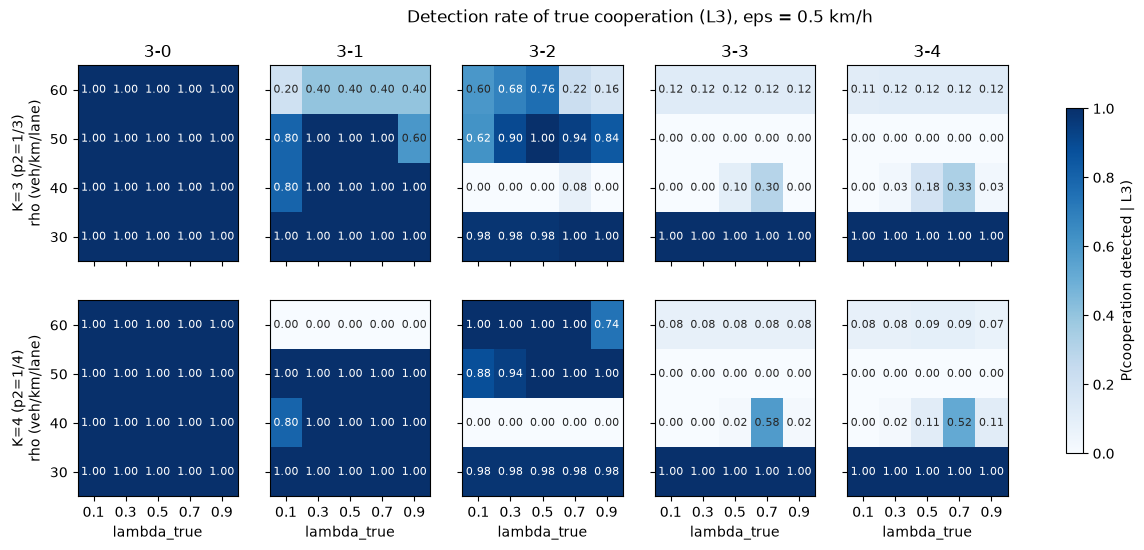

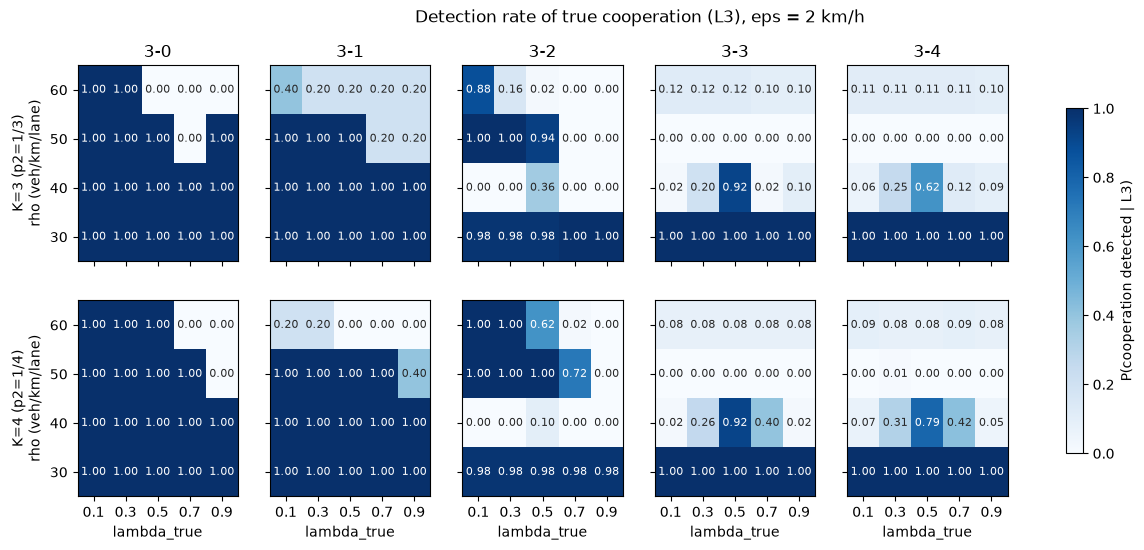

In [15]:
def plot_detection_map(eps):
    d = RES[(RES['group'] == 'E-L3') & (RES['eps'] == eps)]
    cell = d.groupby(['stage', 'K', 'rho', 'lam_target'])['coop'].mean()
    fig, axes = plt.subplots(len(LAYOUTS), len(STAGES), figsize=(3.0 * len(STAGES), 2.8 * len(LAYOUTS)),
                             sharex=True, sharey=True)
    for r, (K, k) in enumerate(LAYOUTS):
        for c, st in enumerate(STAGES):
            ax = axes[r, c]
            M = np.array([[cell.get((st, K, rho, lam), np.nan) for lam in LAM_LIST] for rho in RHO_LIST])
            im = ax.imshow(M, cmap='Blues', vmin=0, vmax=1, origin='lower', aspect='auto')
            for a in range(len(RHO_LIST)):
                for b in range(len(LAM_LIST)):
                    if np.isfinite(M[a, b]):
                        ax.text(b, a, f"{M[a, b]:.2f}", ha='center', va='center', fontsize=8,
                                color='white' if M[a, b] > 0.6 else '0.15')
            ax.set_xticks(range(len(LAM_LIST)), LAM_LIST)
            ax.set_yticks(range(len(RHO_LIST)), RHO_LIST)
            if r == 0:
                ax.set_title(st)
            if c == 0:
                ax.set_ylabel(f"K={K} (p2=1/{K})\nrho (veh/km/lane)")
            if r == len(LAYOUTS) - 1:
                ax.set_xlabel('lambda_true')
    fig.colorbar(im, ax=axes, shrink=0.8, label='P(cooperation detected | L3)')
    fig.suptitle(f"Detection rate of true cooperation (L3), eps = {eps:g} km/h")
    fig.savefig(OUT / f"stage3_detection_map_eps{eps:g}.png", dpi=150, bbox_inches='tight')
    plt.show()


for eps in [0.5, 2.0]:
    plot_detection_map(eps)

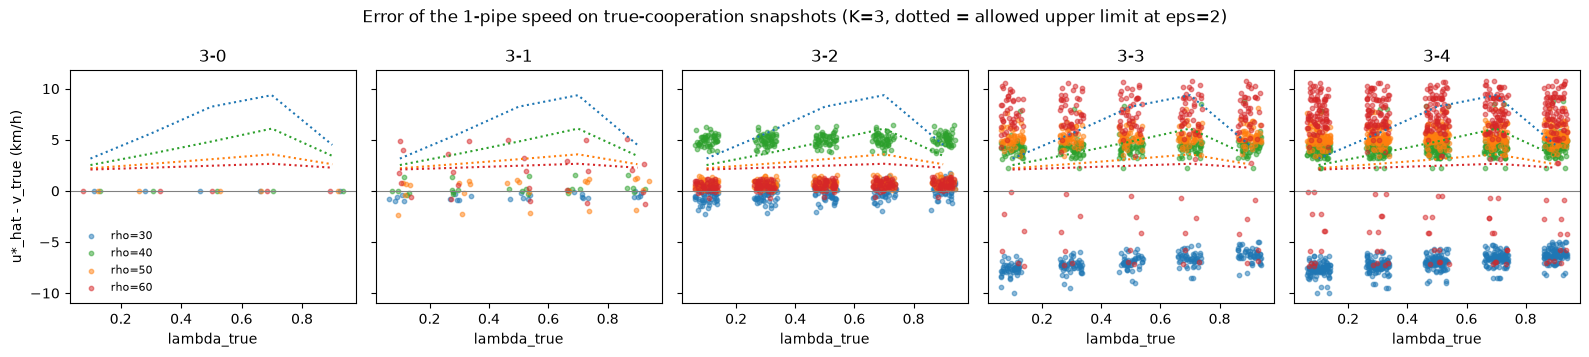

In [16]:
#Δu* = û* − v_true（L3, K=3）。点線 = 許される上限 min(du1, du2) + ε（ε=2）。
#これより上だと片方のクラスが û* − ε より遅くなり non-NE、
#両方の du が ε 以内（û* が近すぎる）だと 1-pipe と判定される
EPS_PLOT = 2.0
d = RES[(RES['group'] == 'E-L3') & (RES['K'] == 3) & (RES['eps'] == EPS_PLOT)]
fig, axes = plt.subplots(1, len(STAGES), figsize=(3.2 * len(STAGES), 3.6), sharey=True)
rng_j = np.random.default_rng(0)
for ax, st in zip(axes, STAGES):
    ds = d[d['stage'] == st]
    for rho in RHO_LIST:
        dr = ds[ds['rho'] == rho]
        ax.scatter(dr['lam_target'] + rng_j.uniform(-0.04, 0.04, len(dr)), dr['du_star'], s=10,
                   color=RHO_COLORS[rho], alpha=0.5, label=f"rho={rho}")
        ref = D_EVAL[(D_EVAL['group'] == 'E-L3') & (D_EVAL['K'] == 3) & (D_EVAL['rho'] == rho)].sort_values('lam_target')
        ax.plot(ref['lam_target'], np.minimum(ref['du1_true'], ref['du2_true']) + EPS_PLOT,
                color=RHO_COLORS[rho], ls=':', lw=1.5)
    ax.axhline(0, color='0.5', lw=0.8)
    ax.set_title(st)
    ax.set_xlabel('lambda_true')
axes[0].set_ylabel('u*_hat - v_true (km/h)')
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Error of the 1-pipe speed on true-cooperation snapshots (K=3, dotted = allowed upper limit at eps={EPS_PLOT:g})")
fig.tight_layout()
fig.savefig(OUT / "stage3_du_star.png", dpi=150)
plt.show()

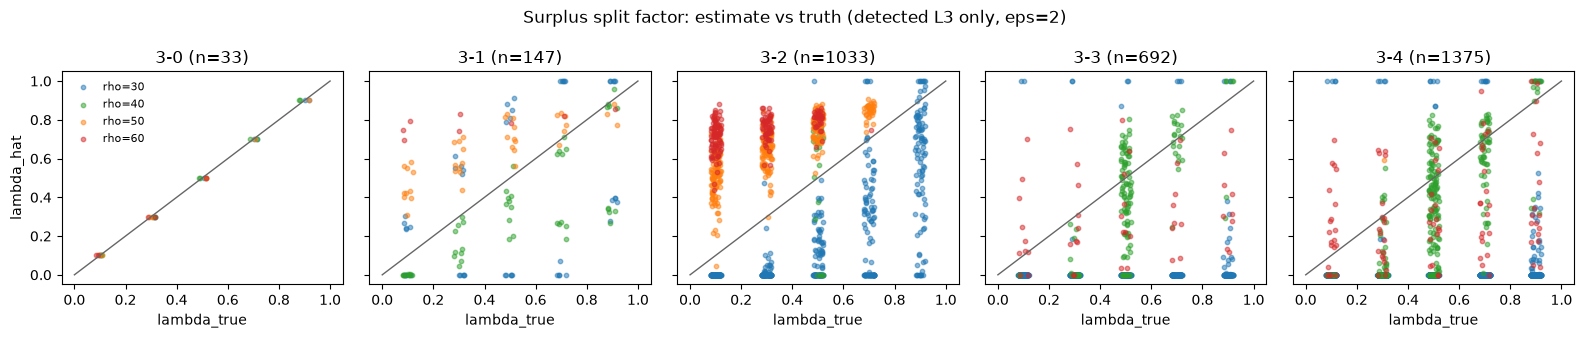

count  median  abs_max
stage lam_target                        
3-0   0.1             8   0.000    0.000
      0.3             8  -0.000    0.000
      0.5             7  -0.000    0.000
      0.7             5  -0.000    0.000
      0.9             5  -0.000    0.000
3-1   0.1            33   0.142    0.696
      0.3            32   0.181    0.531
      0.5            31   0.061    0.500
      0.7            27  -0.049    0.700
      0.9            24  -0.056    0.633
3-2   0.1           292   0.409    0.780
      0.3           256   0.302    0.563
      0.5           250   0.198    0.500
      0.7           136  -0.329    0.700
      0.9            99  -0.242    0.900
3-3   0.1           112  -0.100    0.900
      0.3           133  -0.300    0.700
      0.5           202  -0.500    0.500
      0.7           130  -0.700    0.700
      0.9           115  -0.900    0.900
3-4   0.1           233  -0.100    0.900
      0.3           276  -0.300    0.700
      0.5           360  -0.500    0.500
      0.7           274  -0.700    0.700
      0.9           232  -0.900    0.900

In [17]:
#λ̂ vs λ_true（協力ありと判定された L3 のみ。λ̂ は1スナップショットずつ推定）
d = RES[(RES['group'] == 'E-L3') & (RES['eps'] == EPS_PLOT) & RES['coop']]
fig, axes = plt.subplots(1, len(STAGES), figsize=(3.2 * len(STAGES), 3.4), sharey=True)
for ax, st in zip(axes, STAGES):
    ds = d[d['stage'] == st]
    for rho in RHO_LIST:
        dr = ds[ds['rho'] == rho]
        ax.scatter(dr['lam_true'] + rng_j.uniform(-0.02, 0.02, len(dr)), dr['lam_hat'], s=10,
                   color=RHO_COLORS[rho], alpha=0.5, label=f"rho={rho}")
    ax.plot([0, 1], [0, 1], color='0.4', lw=1)
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-0.05, 1.05)
    ax.set_title(f"{st} (n={len(ds)})")
    ax.set_xlabel('lambda_true')
axes[0].set_ylabel('lambda_hat')
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Surplus split factor: estimate vs truth (detected L3 only, eps={EPS_PLOT:g})")
fig.tight_layout()
fig.savefig(OUT / "stage3_lambda.png", dpi=150)
plt.show()

#λ̂ − λ_true の要約（λ_target ごと）
lam_err = (d.assign(err=d['lam_hat'] - d['lam_true'])
           .groupby(['stage', 'lam_target'])['err'].agg(['count', 'median', lambda x: x.abs().max()])
           .rename(columns={'<lambda_0>': 'abs_max'}))
lam_err.round(3)

In [18]:
#Chen 流の λ̂（協力ありと判定された行すべてで1つ）。n_coop_L3 / n_coop = 混ざっている本物の協力の割合
pool_sum = (POOL.groupby(['stage', 'eps'])
            .agg(n_coop=('n_coop', 'mean'), share_L3=('n_coop_L3', 'sum'), n_tot=('n_coop', 'sum'),
                 lam_pool_median=('lam_pool', 'median'), lam_pool_min=('lam_pool', 'min'),
                 lam_pool_max=('lam_pool', 'max')))
pool_sum['share_L3'] = pool_sum['share_L3'] / pool_sum['n_tot']
pool_sum.drop(columns='n_tot').round(3)

n_coop  share_L3  lam_pool_median  lam_pool_min  lam_pool_max
stage eps                                                                    
3-0   0.000001   40.00     1.000            0.511         0.511         0.511
      0.500000   40.00     1.000            0.511         0.511         0.511
      1.000000   37.00     1.000            0.510         0.510         0.510
      2.000000   36.00     0.917            0.481         0.481         0.481
3-1   0.000001   53.40     0.547            0.517         0.450         0.544
      0.500000   45.80     0.672            0.460         0.415         0.522
      1.000000   39.60     0.793            0.417         0.356         0.483
      2.000000   33.60     0.875            0.322         0.267         0.440
3-2   0.000001   34.16     0.650            0.664         0.514         0.743
      0.500000   33.70     0.777            0.600         0.435         0.701
      1.000000   31.72     0.810            0.556         0.321         0.675
      2.000000   24.34     0.849            0.431         0.070         0.536
3-3   0.000001   25.00     0.462            0.000         0.000         0.962
      0.500000   25.44     0.472            0.000         0.000         0.962
      1.000000   25.88     0.484            0.000         0.000         0.962
      2.000000   27.20     0.509            0.000         0.000         0.962
3-4   0.000001   25.10     0.471            0.000         0.000         1.000
      0.500000   25.74     0.479            0.000         0.000         1.000
      1.000000   26.24     0.490            0.000         0.000         1.000
      2.000000   27.12     0.507            0.000         0.000         1.000

## 9. 結果のまとめ（2026-11-12 実行、R=50、3-4 は観測ノイズ2回/フィット）

**検出率 P(協力あり | L3)** と **偽協力率**（ε = 2 km/h、ρ ごと）

| 段階 | L3 ρ30 | ρ40 | ρ50 | ρ60 | L4 全体 | mix ρ30 | mix 全体 |
|---|---|---|---|---|---|---|---|
| 3-0 oracle | 1.00 | 1.00 | 0.80 | 0.50 | 0.13 | 0.00 | 0.00 |
| 3-1 形の誤差だけ | 1.00 | 1.00 | 0.78 | 0.16 | 0.10 | 0.00 | 0.05 |
| 3-2 ＋ノイズ・件数 | 0.98 | 0.05 | 0.67 | 0.37 | 0.09 | 0.15 | 0.04 |
| 3-3 ＋速度範囲の制限 | 1.00 | 0.29 | 0.00 | 0.10 | 0.11 | **1.00** | 0.27 |
| 3-4 ＋観測ノイズ | 1.00 | 0.28 | 0.00 | 0.10 | 0.11 | **1.00** | 0.27 |

1. **3-0（推定の問題がなくても）**：ε = 2 では ρ ≥ 50 で見逃す（ρ60 で半分）。中身はすべて「1-pipe と判定」= du1, du2 が両方 ε 以内。同じ理由で、帯の端の L4 の一部（ρ ≥ 50）が協力ありになる。ε を小さくすると L3 は全部取れる（ε ≤ 0.5 で 100%）。λ̂ は1スナップショットで λ_true を回収（差 2e-6）
2. **結果は û* が v_true からどちらにずれるかでほぼ決まる**。L3 で必要な精度は du の大きさ（ρ30 で数〜十数 km/h、ρ60 で 1 km/h 未満）
   - û* が低い → 混合も L4 も「協力あり」（3-3 の ρ30：û* が −8.5 km/h → L3, mix とも 100%、L4 も 33%）
   - û* が高い → L3 が non-NE（3-3 の ρ ≥ 40：+4〜+7 km/h）
3. **3-1（ノイズなし・件数十分・全速度範囲）でも誤差が出る**：Underwood が OV のトラック曲線に合わない（T-T・T-C の MAE がノイズなしで約 10.5 km/h、uf は上限 150 に張り付く）。それでも û* の誤差は ρ ≤ 50 で 1 km/h 未満で、検出は 3-0 とほぼ同じ。ρ60 だけ +3.3 km/h ずれて検出 16%
   - ρ60 の v_true（7〜8 km/h）が、フィットしたロジスティックの下限 ub（中央値 12.3 km/h）より低い。論文形の乗用車関数は ub より遅い速度を表せない（3-3 は ub の中央値 16.1 km/h → ρ50（12 km/h）でも同じことが起きる）
   - ε ≈ 0 では混合の 60% が協力ありになる（û* が約 1 km/h 低い）。ε = 2 で 5% まで下がる
4. **3-2（NGSIM 並みのノイズ・件数）**：a2 はほぼ正確（0.452 ± 0.005）だが、b1 がばらつく（2.13〜3.07）。ρ40 で û* が +5 km/h 高くなり、検出 5% に落ちる。ずれの大きさは ρ によって不規則
5. **3-3（推定範囲 15〜60 km/h）**：範囲の外の評価点（ρ30 は 53〜61 km/h で観測速度は最大 83 km/h、ρ50・60 は 15 km/h 未満）で û* が大きくずれる。**どの ρ でも、L3 と混合を見分けられない**（ρ30 は全部協力あり、ρ ≥ 40 はほぼ全部協力なし）
6. **3-4**：観測ノイズ（σ = 5/√台数 ≈ 0.5〜1 km/h）の影響は 3-3 の関数の誤差に比べて小さく、結果はほぼ同じ
7. **λ̂ は oracle 以外では λ_true を回収できない**：3-1 からばらつきが大きく、3-2 の ρ50・60 では λ_true によらず 0.5〜0.85。3-3 では協力ありと判定された L3 の 74% で λ̂ が下限 0 に張り付く（NGSIM で λ̂ が下限に張り付いたのと同じ型）。Chen 流の λ̂（協力ありの全行で1つ）は、3-3 で中央値 0。協力ありの中に混合・L4 が約半分混ざっている

**Stage 3 の問いへの答え（この正解のもとで）**：関数形が正しく推定範囲が評価点を覆えば、du が ε より大きい低密度側では検出できる。しかし協力の検出は、û* の誤差が du（数 km/h、高密度では 1 km/h 未満）より小さいことに頼っている。関数形の誤差、少ない T-T / T-C の記録、推定範囲の外への外挿のどれでも、この程度の誤差は出る。NGSIM に近い条件（3-3, 3-4）では、協力と混合を区別できなかった

注意：OV の形・ノイズの大きさ・速度範囲・REC_PER_PAIR は仮置き。結論は「この正解なら」という条件付き。ρ30 の外挿は、評価点の速度が範囲の上端を超えるため（評価点の置き方による）
